[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LRCole3/pre-training-pathway/blob/main/02_rnns_attention_elmo.ipynb)

# 02 · Recurrent Models, Attention and Contextual Pretraining: Carrying a Memory, and Its Limits

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Counting and embeddings | Count n-grams; learn word vectors | A first language model; similar words get similar vectors | Fixed window; one vector per word |
| **02** | **RNNs, attention, ELMo** | **Carry a state; look back with attention; reuse the pretrained network** | **Context beyond a window; contextual features** | **Memory fades with distance; no parallel training** |
| 03 | The transformer | Attention only, then today's block (RoPE, RMSNorm, SwiGLU, GQA, MoE) | Direct access to any earlier token; parallel training | Needs an objective and a transfer recipe |
| 04 | Objectives and transfer | Causal, masked and span-corruption pretraining | Representations that transfer with few labels | No objective wins everything; optimisation untested |
| 05 | Making it scale | Tokenisers, the optimiser recipe, scaling laws | A recipe that keeps improving with size | Discrete tokens only |
| 06 | VAE, GAN, pixel models | Generative models for images before diffusion | Sampling images at all | Blur, mode collapse, slow sampling |
| 07 | Diffusion design space | Denoise step by step; schedule, target, weighting | Quality and coverage together | Pixel space, MLP backbone, no text |
| 08 | Encoders, CLIP, latent diffusion | Pretrain the parts: vision encoder, text-image model, autoencoder | Conditioning and compression | The backbone still does not scale |
| 09 | Diffusion transformers | Patch tokens, flow matching, training accelerators | A scalable denoiser | Base models still need post-training |
| 10 | Capstone | One backbone, three objectives, two modalities | A unified view of pretraining | The post-training series starts here |

Notebook 01 ended with two measured limits: a model with a **fixed window** cannot recall anything outside it, and
**one vector per word** cannot represent word order. Recurrent networks answer both. They read a sequence one token
at a time and carry a **hidden state** forward, so in principle nothing is ever out of reach ([Elman, 1990](https://doi.org/10.1207/s15516709cog1402_1)), and the
state at each word depends on everything before it.

In practice the plain version cannot learn long-range dependencies ([Bengio et al., 1994](https://doi.org/10.1109/72.279181)). This notebook follows the fixes
in the order they were made: **gating** (the LSTM, [Hochreiter & Schmidhuber, 1997](https://doi.org/10.1162/neco.1997.9.8.1735)), **attention** over past states
([Bahdanau et al., 2014](https://arxiv.org/abs/1409.0473)), and then the step that made these models *pretrained* models: reusing a network trained as a
language model for a different task (ELMo, [Peters et al., 2018](https://arxiv.org/abs/1802.05365); ULMFiT, [Howard & Ruder, 2018](https://arxiv.org/abs/1801.06146)).

## Learning objectives

1. Explain why gradients vanish or explode in a recurrent network, and measure it.
2. Show what gating changes, and where a fixed-size state still fails.
3. Implement attention over past states, read attention maps, and compare additive with dot-product scoring.
4. Reuse a pretrained language model for a labelled task and compare it with training from scratch.

**Runtime:** about 7 minutes on a laptop CPU (six recurrent models are trained).

In [1]:
# Setup. Locally this only adds the repo to the path. In Colab it first clones the repository (untested path).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("prelib"):
    os.system("git clone -q https://github.com/LRCole3/pre-training-pathway.git"); os.chdir("pre-training-pathway")
sys.path.insert(0, ".")

import time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from prelib import world as W, classic as C, recurrent as R, viz, metrics, set_seed
viz.style()
torch.set_num_threads(min(8, torch.get_num_threads()))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
train, test = W.corpus("train"), W.corpus("test")
dists = list(W.RECALL_DISTANCES)
COL = {"plain RNN": viz.SKY, "GRU": viz.GREEN, "LSTM": viz.PINK, "LSTM, 128 units": "#7A3E6B",
       "LSTM + dot-product attention": viz.BLUE, "LSTM + additive attention": viz.ORANGE}
models, res = {}, {}
def fit(name, **kw):
    # every model in this notebook: same data, 1,500 steps, same optimiser
    set_seed(0)
    m = R.RecurrentLM(**kw)
    t0 = time.time()
    C.train_lm(m, train["tokens"], steps=1500, batch=64, lr=2e-3)
    r = W.evaluate_lm(m.logprobs)
    r["seconds"] = time.time() - t0
    r["natural"] = W.natural_recall(m.logprobs)
    models[name], res[name] = m, r
    print(f"{name:30s} gap to floor {r['gap']:.3f}   recall at 8 / 32 / 56 tokens: {r['recall'][8]:.2f} / {r['recall'][32]:.2f} / {r['recall'][56]:.2f}   ({r['seconds']:.0f}s)")

## 1. A network with a memory

A recurrent network keeps a vector $h_t$, the hidden state, and updates it with each new token:
$$h_t = \tanh(W_x\, x_t + W_h\, h_{t-1} + b), \qquad p(x_{t+1} \mid x_{\le t}) = \text{softmax}(W_o\, h_t).$$
The same weights are used at every position, so the model has no window: $h_t$ can depend on every earlier token.

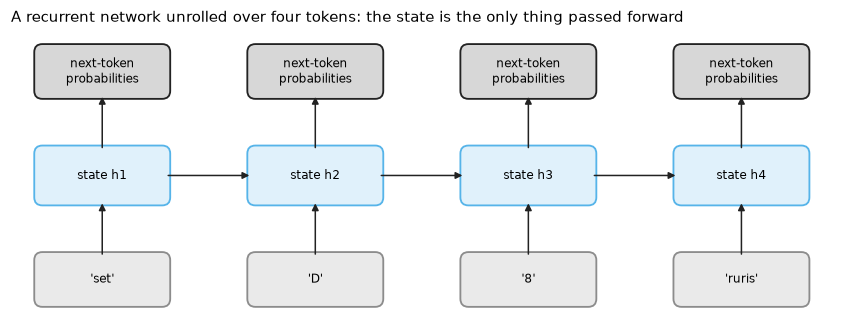

plain RNN                      gap to floor 0.326   recall at 8 / 32 / 56 tokens: 0.13 / 0.11 / 0.12   (13s)


In [2]:
fig, ax = plt.subplots(figsize=(9, 2.9))
boxes, arrows = [], []
for i, tok in enumerate(["set", "D", "8", "ruris"]):
    x = i * 2.1
    boxes += [(x, 0, 1.3, 0.5, f"'{tok}'", viz.GREY), (x, 1.0, 1.3, 0.55, f"state h{i + 1}", viz.SKY), (x, 2.05, 1.3, 0.5, "next-token\nprobabilities", viz.BLACK)]
    arrows += [(x + 0.65, 0.5, x + 0.65, 1.0), (x + 0.65, 1.55, x + 0.65, 2.05)]
    if i:
        arrows.append((x - 0.8, 1.275, x, 1.275))
viz.diagram(ax, boxes, arrows, fontsize=8)
ax.set_title("A recurrent network unrolled over four tokens: the state is the only thing passed forward")
plt.show()
fit("plain RNN", cell="rnn", d=64)

The plain RNN models the filler words better than the fixed-window models of notebook 01, but look at its recall: it
is at chance (12.5%) at every distance, including three tokens. It has a memory in principle and cannot use it.

## 2. Why: gradients vanish (or explode)

To learn that a token 30 steps back matters, the training signal has to travel 30 steps back through the network.
Each step multiplies it by $W_h$ and by the slope of the nonlinearity. Multiply 30 numbers that are a little below 1
and you get almost nothing; a little above 1 and you get something enormous ([Bengio et al., 1994](https://doi.org/10.1109/72.279181), [Pascanu et al., 2012](https://arxiv.org/abs/1211.5063)).

The left panel is a controlled experiment on untrained networks whose recurrent weights are scaled by a chosen
factor. The right panel measures the same thing in the plain RNN we just trained: how strongly the loss at the last
token depends on the input at each earlier position.

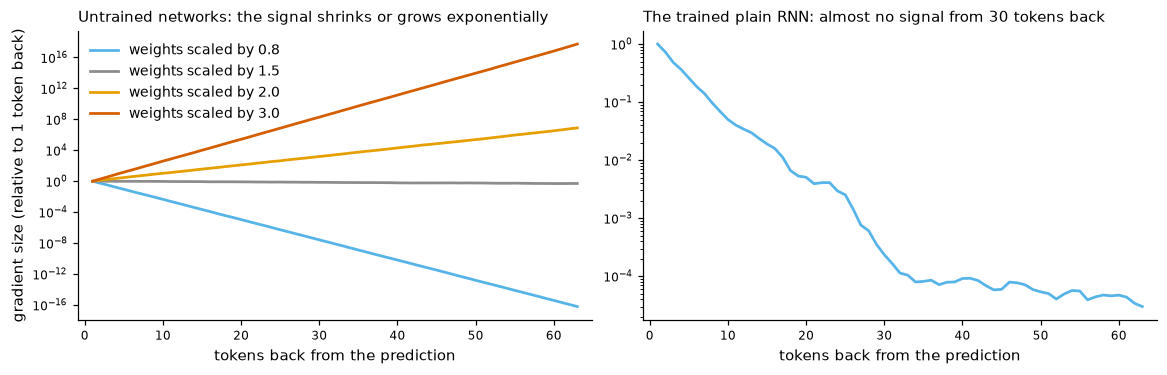

plain RNN, gradient relative to 1 token back: {4: '3.7e-01', 16: '1.6e-02', 32: '1.1e-04', 60: '4.7e-05'}


In [3]:
def scaled_rnn(rho):
    set_seed(0)
    m = R.RecurrentLM("rnn", d=64)
    m.rnn = torch.nn.RNN(64, 64, batch_first=True, nonlinearity="relu")
    with torch.no_grad():
        q, _ = torch.linalg.qr(torch.randn(64, 64))
        m.rnn.weight_hh_l0.copy_(rho * q)            # all singular values of the recurrent matrix equal rho
    return m
sample = test["tokens"][:200]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3))
back = np.arange(1, W.DOC_LEN)
for rho, col in zip([0.8, 1.5, 2.0, 3.0], [viz.SKY, viz.GREY, viz.ORANGE, viz.VERMILION]):
    g = R.gradient_reach(scaled_rnn(rho), sample)
    axes[0].plot(back, g / g[0], color=col, label=f"weights scaled by {rho}")
axes[0].set_yscale("log"); axes[0].set_xlabel("tokens back from the prediction"); axes[0].set_ylabel("gradient size (relative to 1 token back)")
axes[0].set_title("Untrained networks: the signal shrinks or grows exponentially"); axes[0].legend()
g_rnn = R.gradient_reach(models["plain RNN"], sample)
axes[1].plot(back, g_rnn / g_rnn[0], color=COL["plain RNN"])
axes[1].set_yscale("log"); axes[1].set_xlabel("tokens back from the prediction"); axes[1].set_title("The trained plain RNN: almost no signal from 30 tokens back")
plt.show()
print("plain RNN, gradient relative to 1 token back:", {k: f"{g_rnn[k - 1] / g_rnn[0]:.1e}" for k in [4, 16, 32, 60]})

On a log axis, exponential decay is a straight line going down and exponential growth a straight line going up,
and that is what the controlled experiment shows: a factor of 0.8 shrinks the signal, factors of 2 and 3 blow it up, and
1.5 roughly cancels the loss from the nonlinearity. In the trained RNN the signal from 32 tokens back is about ten
thousand times weaker than from one token back. The network is never told, in any usable way, that the binding mattered.

### Design choice: gradient clipping

The exploding case has a simple remedy: if the gradient's overall size exceeds a threshold, scale it down before the
update ([Pascanu et al., 2012](https://arxiv.org/abs/1211.5063)). We test it where it should matter, on the network whose weights were scaled by 2.

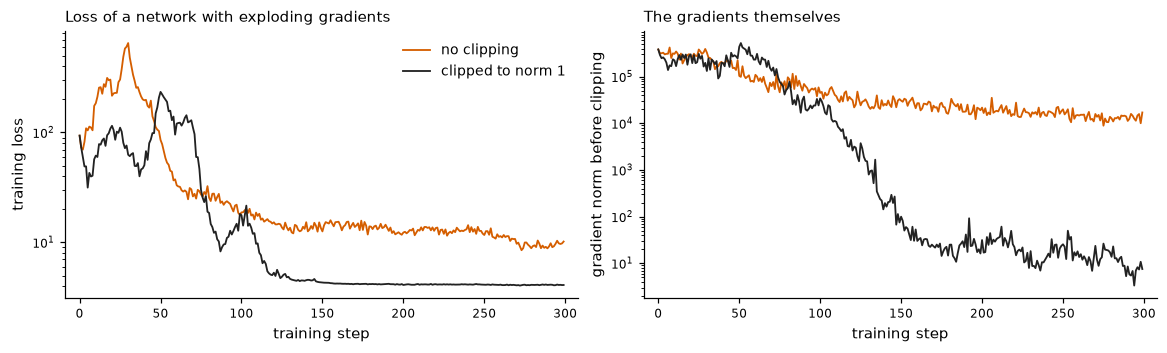

{'no clipping': 'final loss 9.49, largest gradient norm 4.22e+05', 'clipped to norm 1': 'final loss 4.11, largest gradient norm 5.26e+05'}


In [4]:
def train_track(model, clip, steps=300):
    set_seed(0)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3); it = W.batches(train["tokens"], 64, 0); out = []
    for _ in range(steps):
        x = next(it)
        loss = F.cross_entropy(model(x)[:, 1:].reshape(-1, W.VOCAB), x[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward()
        norm = float(torch.nn.utils.clip_grad_norm_(model.parameters(), clip if clip else 1e12))
        opt.step(); out.append((loss.item(), norm))
    return np.array(out)
clip_runs = {"no clipping": train_track(scaled_rnn(2.0), None), "clipped to norm 1": train_track(scaled_rnn(2.0), 1.0)}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.1))
for (name, h), col in zip(clip_runs.items(), [viz.VERMILION, viz.BLACK]):
    axes[0].plot(h[:, 0], color=col, label=name, lw=1.2); axes[1].plot(h[:, 1], color=col, lw=1.2)
axes[0].set_yscale("log"); axes[0].set_xlabel("training step"); axes[0].set_ylabel("training loss"); axes[0].legend()
axes[0].set_title("Loss of a network with exploding gradients")
axes[1].set_yscale("log"); axes[1].set_xlabel("training step"); axes[1].set_ylabel("gradient norm before clipping"); axes[1].set_title("The gradients themselves")
plt.show()
print({k: f"final loss {h[-20:, 0].mean():.2f}, largest gradient norm {h[:, 1].max():.3g}" for k, h in clip_runs.items()})

**Reading the result.** Without clipping, the gradients stay around ten thousand and the loss ends near 9.5, worse
than guessing uniformly (4.39). With clipping every update is bounded, the weights drift to a calmer region where the
gradients themselves shrink, and the loss ends at 4.1. That is still a poor model: clipping treats the symptom of a
badly scaled network and does not repair it. All the standard models in this notebook are trained with clipping at norm 1
as a safety net. With their default initialisation the gradients never grew large, so it rarely acted. Clipping remains
part of the standard recipe for training transformers.

## 3. Design choice: gating (LSTM and GRU)

Clipping does nothing for the *vanishing* case. The **LSTM** ([Hochreiter & Schmidhuber, 1997](https://doi.org/10.1162/neco.1997.9.8.1735)) changes the architecture instead.
It adds a second state, the cell $c_t$, that is updated by addition rather than by repeated multiplication:
$$c_t = f_t \odot c_{t-1} + i_t \odot g_t, \qquad h_t = o_t \odot \tanh(c_t).$$
The **forget gate** $f_t$, **input gate** $i_t$ and **output gate** $o_t$ are numbers between 0 and 1 computed from
the current input and state. When $f_t \approx 1$ and $i_t \approx 0$, the cell is copied unchanged and the training
signal passes back through that step unchanged as well. The **GRU** ([Cho et al., 2014](https://arxiv.org/abs/1406.1078)) is a later simplification with two
gates and no separate cell.

GRU                            gap to floor 0.243   recall at 8 / 32 / 56 tokens: 0.15 / 0.13 / 0.11   (39s)
LSTM                           gap to floor 0.170   recall at 8 / 32 / 56 tokens: 0.85 / 0.66 / 0.54   (44s)


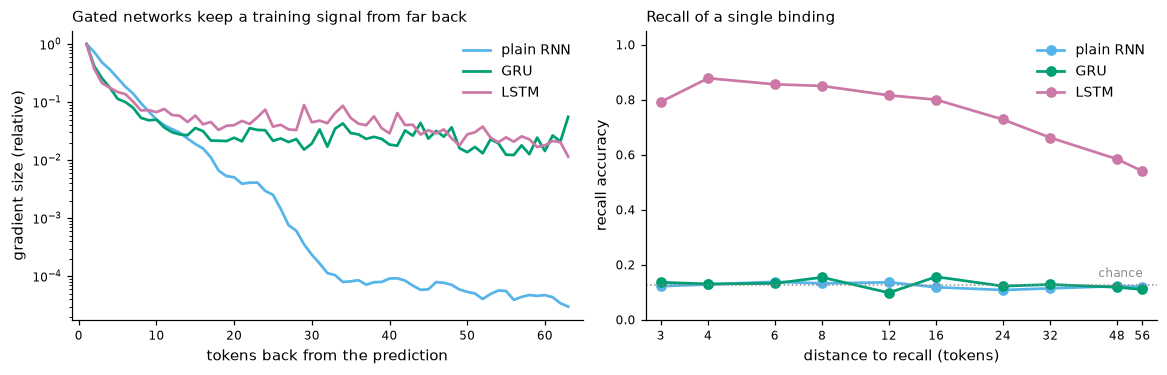

In [5]:
fit("GRU", cell="gru", d=64)
fit("LSTM", cell="lstm", d=64)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3))
for name in ["plain RNN", "GRU", "LSTM"]:
    g = R.gradient_reach(models[name], sample)
    axes[0].plot(back, g / g[0], color=COL[name], label=name)
    axes[1].plot(dists, [res[name]["recall"][d] for d in dists], "o-", color=COL[name], label=name)
axes[0].set_yscale("log"); axes[0].set_xlabel("tokens back from the prediction"); axes[0].set_ylabel("gradient size (relative)")
axes[0].set_title("Gated networks keep a training signal from far back"); axes[0].legend()
axes[1].axhline(1 / W.N_VAL, color=viz.GREY, ls=":", lw=1); axes[1].text(56, 1 / W.N_VAL + 0.03, "chance", ha="right", fontsize=8, color=viz.GREY)
axes[1].set_xscale("log", base=2); axes[1].set_xticks(dists); axes[1].set_xticklabels(dists); axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel("distance to recall (tokens)"); axes[1].set_ylabel("recall accuracy"); axes[1].set_title("Recall of a single binding"); axes[1].legend()
plt.show()

**Reading the result.** Both gated networks still receive one to two percent of the training signal from 60 tokens back,
hundreds of times more than the plain RNN (left). The LSTM turns that into recall: about 85% at short distances, fading to
54% at 56 tokens. The GRU does not, in this run. It has the same gradient reach and a lower loss than the plain RNN, but
its recall stays at chance. This is one seed and 1,500 training steps; in a development run with a 128-unit state, the
LSTM and the GRU both reached perfect single-binding recall. Gating makes long-range learning possible. It does not make
it automatic.

### Looking inside: the cell state as a memory

The figure follows one document through the trained LSTM. The top strip is the document: a binding at the start and
its query 24 tokens later. Below are the ten cell units that changed most when the binding was read.

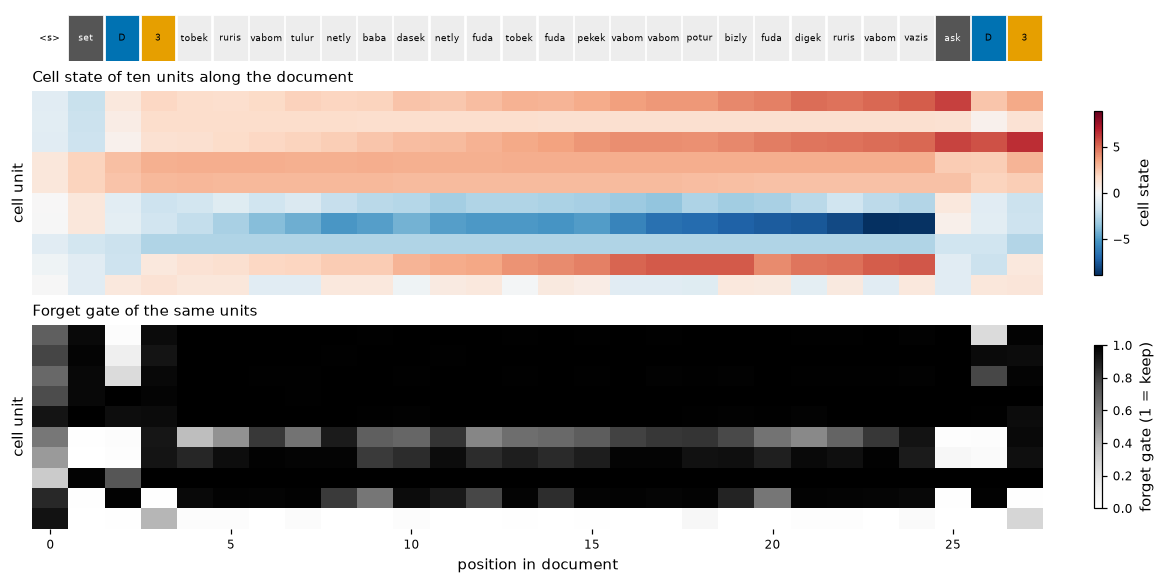

mean forget gate of these units between the binding and the query: 0.85


In [6]:
toks, target = W.recall_set(24)
doc = toks[1][:target + 1]
trace = R.lstm_trace(models["LSTM"], doc)
units = np.argsort(-np.abs(trace["cell state"][3] - trace["cell state"][0]))[:10]
fig, axes = plt.subplots(3, 1, figsize=(10.5, 5.2), gridspec_kw=dict(height_ratios=[0.5, 2, 2]))
viz.token_strip(axes[0], [W.WORDS[t] for t in doc], colors=viz.doc_colors(doc), wrap=len(doc), fontsize=6)
lim = np.abs(trace["cell state"][:, units]).max()
viz.heat(axes[1], trace["cell state"][:, units].T, cmap="RdBu_r", vmin=-lim, vmax=lim, cbar="cell state")
axes[1].set_ylabel("cell unit"); axes[1].set_yticks([]); axes[1].set_xticks([])
axes[1].set_title("Cell state of ten units along the document")
viz.heat(axes[2], trace["forget gate"][:, units].T, cmap="Greys", vmin=0, vmax=1, cbar="forget gate (1 = keep)")
axes[2].set_ylabel("cell unit"); axes[2].set_yticks([]); axes[2].set_xlabel("position in document")
axes[2].set_title("Forget gate of the same units")
plt.show()
keep = trace["forget gate"][4:target - 2, units].mean()
print(f"mean forget gate of these units between the binding and the query: {keep:.2f}")

When the binding is read (positions 1 to 3), several units jump to large positive or negative values, and most of
them hold those values until the query arrives. The lower panel shows how: the forget gates of these units are mostly
dark, meaning close to 1 (keep), and average 0.85 between the binding and the query. This is the memory, and it leaks a
little: a gate below 1 shrinks the stored value at every step, which is why recall fades with distance.

### The remaining limit: everything must fit in the state

The recall test above uses one binding. Ordinary documents in our language keep up to three bindings alive at once,
and the LSTM has to hold all of them, plus its beliefs about topic and style, in one fixed-size vector. We test a
larger state as well.

LSTM, 128 units                gap to floor 0.080   recall at 8 / 32 / 56 tokens: 1.00 / 1.00 / 1.00   (69s)


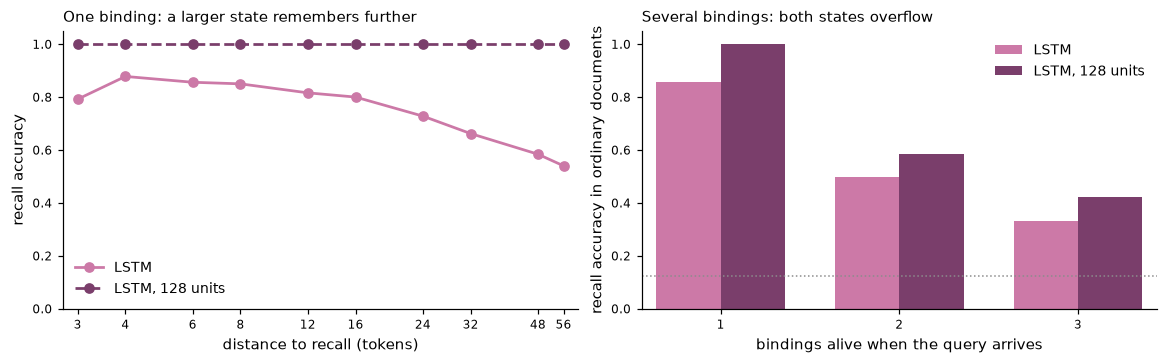

,LSTM,"LSTM, 128 units"
bindings,,
1,0.86,1.00
2,0.50,0.58
3,0.33,0.42


In [7]:
fit("LSTM, 128 units", cell="lstm", d=128)
def by_bindings(name):
    return res[name]["natural"].groupby("bindings").correct.mean()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2))
for name, ls in [("LSTM", "-"), ("LSTM, 128 units", "--")]:
    axes[0].plot(dists, [res[name]["recall"][d] for d in dists], "o", ls=ls, color=COL[name], label=name)
axes[0].set_xscale("log", base=2); axes[0].set_xticks(dists); axes[0].set_xticklabels(dists); axes[0].set_ylim(0, 1.05)
axes[0].set_xlabel("distance to recall (tokens)"); axes[0].set_ylabel("recall accuracy"); axes[0].set_title("One binding: a larger state remembers further"); axes[0].legend()
x = np.arange(1, 4)
for k, name in enumerate(["LSTM", "LSTM, 128 units"]):
    axes[1].bar(x + (k - 0.5) * 0.36, by_bindings(name).reindex(x).values, 0.36, color=COL[name], label=name)
axes[1].axhline(1 / W.N_VAL, color=viz.GREY, ls=":", lw=1)
axes[1].set_xticks(x); axes[1].set_xlabel("bindings alive when the query arrives"); axes[1].set_ylabel("recall accuracy in ordinary documents")
axes[1].set_ylim(0, 1.05); axes[1].set_title("Several bindings: both states overflow"); axes[1].legend()
plt.show()
display(pd.DataFrame({n: by_bindings(n) for n in ["LSTM", "LSTM, 128 units"]}).round(2))

**Reading the result.** Doubling the state to 128 units makes single-binding recall perfect at every distance. But in
ordinary documents, where a second or third binding may be alive, both sizes fail: the 64-unit model answers 50% and
33% of queries correctly with two and three bindings alive, and the 128-unit model 58% and 42%. Whatever must be
remembered has to fit into one vector, alongside everything else the model tracks. A larger state helps, at a cost that
grows with the square of its size, and the bottleneck stays.

### Try it: where does each network lose the key?

Static preview at the default settings {'distance': 16}. Run the notebook to get the controls.


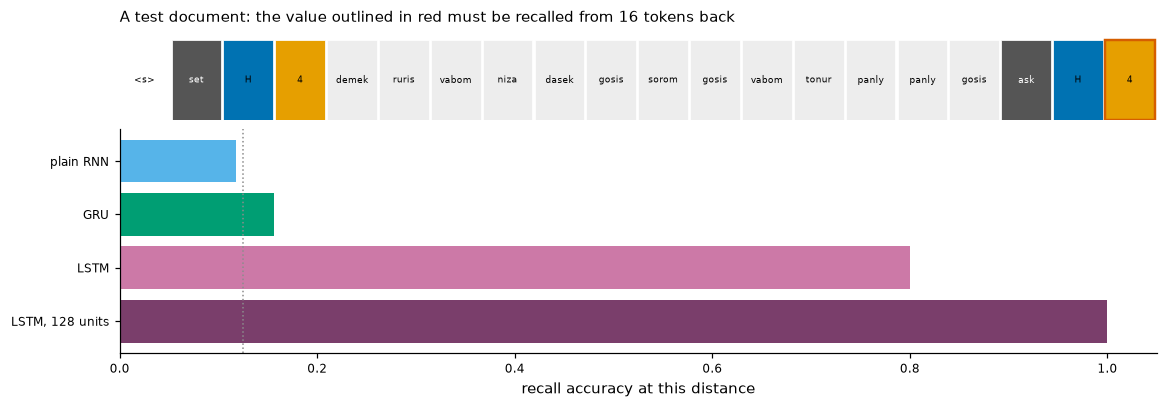

In [8]:
def recall_explorer(distance=16):
    t, pos = W.recall_set(distance)
    doc = t[0][:pos + 1]
    fig, axes = plt.subplots(2, 1, figsize=(10.5, 3.6), gridspec_kw=dict(height_ratios=[0.8, 2]))
    viz.token_strip(axes[0], [W.WORDS[i] for i in doc], colors=viz.doc_colors(doc), wrap=max(len(doc), 20), fontsize=6,
                    edge=[None] * (len(doc) - 1) + [viz.VERMILION])
    axes[0].set_title(f"A test document: the value outlined in red must be recalled from {distance} tokens back")
    names = ["plain RNN", "GRU", "LSTM", "LSTM, 128 units"]
    axes[1].barh(names[::-1], [res[n]["recall"][distance] for n in names][::-1], color=[COL[n] for n in names][::-1])
    axes[1].axvline(1 / W.N_VAL, color=viz.GREY, ls=":", lw=1); axes[1].set_xlim(0, 1.05); axes[1].set_xlabel("recall accuracy at this distance")
    plt.show()
viz.explore(recall_explorer, distance=[16] + [d for d in dists if d != 16])

## 4. Attention: look back instead of remembering

The state is a bottleneck because it is the only route from the past to the present. **Attention**, introduced for
translation by [Bahdanau et al., 2014](https://arxiv.org/abs/1409.0473) on top of the encoder–decoder of [Sutskever et al., 2014](https://arxiv.org/abs/1409.3215), adds a second route. At each
step the model compares its current state $h_t$ (the *query*) with every earlier state $h_j$ (the *keys*), turns the
scores into weights that sum to one, and reads the weighted average:
$$\alpha_{tj} = \text{softmax}_j\big(\text{score}(h_t, h_j)\big), \qquad c_t = \sum_{j<t} \alpha_{tj}\, h_j, \qquad p(x_{t+1}) = \text{softmax}\big(W_o [h_t; c_t]\big).$$
Nothing needs to be carried: a binding made 50 tokens ago is one step away.

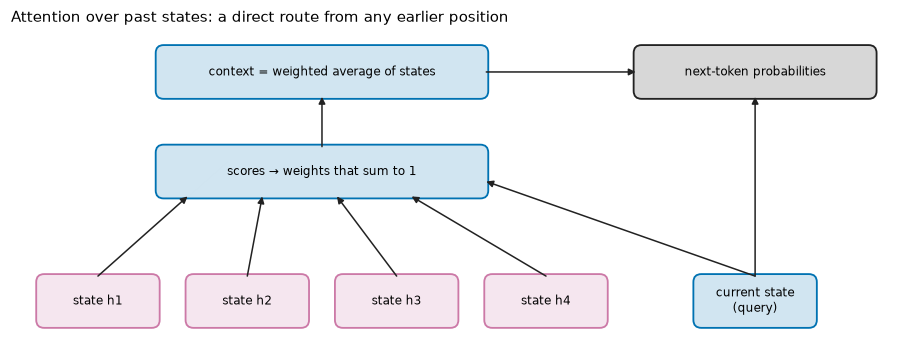

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 3.1))
boxes = [(i * 1.5, 0, 1.2, 0.5, f"state h{i + 1}", viz.PINK) for i in range(4)] + [(6.6, 0, 1.2, 0.5, "current state\n(query)", viz.BLUE)]
boxes += [(1.2, 1.3, 3.3, 0.5, "scores \u2192 weights that sum to 1", viz.BLUE), (1.2, 2.3, 3.3, 0.5, "context = weighted average of states", viz.BLUE),
          (6.0, 2.3, 2.4, 0.5, "next-token probabilities", viz.BLACK)]
arrows = [(i * 1.5 + 0.6, 0.5, 1.5 + i * 0.75, 1.3) for i in range(4)] + [(7.2, 0.5, 4.5, 1.45), (2.85, 1.8, 2.85, 2.3), (4.5, 2.55, 6.0, 2.55), (7.2, 0.5, 7.2, 2.3)]
viz.diagram(ax, boxes, arrows, fontsize=8); ax.set_title("Attention over past states: a direct route from any earlier position")
plt.show()

### Design choice: how to score a query against a key

* **Additive** attention ([Bahdanau et al., 2014](https://arxiv.org/abs/1409.0473)) uses a small network: $\text{score} = v^\top \tanh(W_q h_t + W_k h_j)$.
* **Dot-product** attention ([Luong et al., 2015](https://arxiv.org/abs/1508.04025)) uses a product: $\text{score} = (W_q h_t)^\top (W_k h_j) / \sqrt{d}$.

The dot product can be computed for all pairs at once as a single matrix multiplication, which is why the transformer
in notebook 03 uses it. We train both on top of the 64-unit LSTM.

LSTM + dot-product attention   gap to floor 0.049   recall at 8 / 32 / 56 tokens: 1.00 / 1.00 / 1.00   (54s)
LSTM + additive attention      gap to floor 0.113   recall at 8 / 32 / 56 tokens: 0.98 / 0.85 / 0.77   (84s)


,gap to floor,"recall, 1 binding alive",2 alive,3 alive,training time (s)
LSTM,0.170,0.856,0.498,0.333,43.919
"LSTM, 128 units",0.080,1.000,0.583,0.421,68.919
LSTM + additive attention,0.113,0.988,0.552,0.400,83.641
LSTM + dot-product attention,0.049,1.000,0.999,0.999,53.847


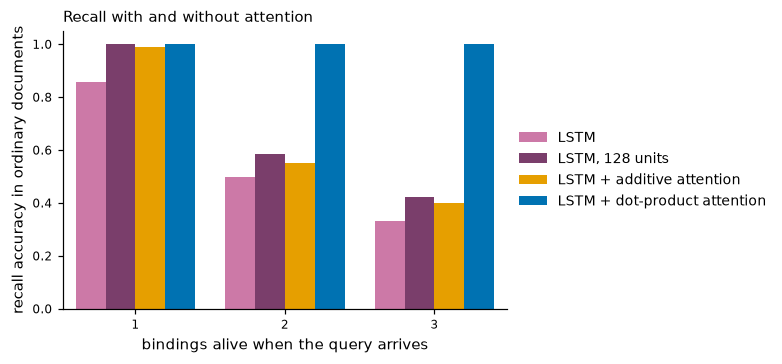

In [10]:
fit("LSTM + dot-product attention", cell="lstm", d=64, attention="dot")
fit("LSTM + additive attention", cell="lstm", d=64, attention="additive")
names = ["LSTM", "LSTM, 128 units", "LSTM + additive attention", "LSTM + dot-product attention"]
att = pd.DataFrame({"gap to floor": [res[n]["gap"] for n in names],
                    "recall, 1 binding alive": [by_bindings(n)[1] for n in names], "2 alive": [by_bindings(n)[2] for n in names],
                    "3 alive": [by_bindings(n)[3] for n in names], "training time (s)": [res[n]["seconds"] for n in names]}, index=names)
display(att.round(3))
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(1, 4)
for k, n in enumerate(names):
    ax.bar(x + (k - 1.5) * 0.2, by_bindings(n).reindex(x).values, 0.2, color=COL[n], label=n)
ax.set_xticks(x); ax.set_xlabel("bindings alive when the query arrives"); ax.set_ylabel("recall accuracy in ordinary documents"); ax.set_ylim(0, 1.05)
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5)); ax.set_title("Recall with and without attention")
plt.show()

**Reading the result.** Dot-product attention solves the problem: recall is essentially perfect with one, two or three
bindings alive, and the gap to the floor falls to 0.05 nats per token, the lowest so far, with a 64-unit state. Additive
attention, in the same budget, learned only the single-binding case and took about 1.5 times as long to train. Again this
is one seed; in a development run with a 128-unit state, additive attention also reached near-perfect recall. What the
comparison supports is the cost argument: the dot product is cheaper, and here it also learned faster.

### What the attention looks at

The animation follows the dot-product model through a test document. At each step the token being read is outlined,
and earlier tokens are shaded by how much attention they receive. Watch the shading when the model reaches a key
after `ask`.

saved figures/nb02_attention_reading.gif  (38 frames drawn, 402 kB)


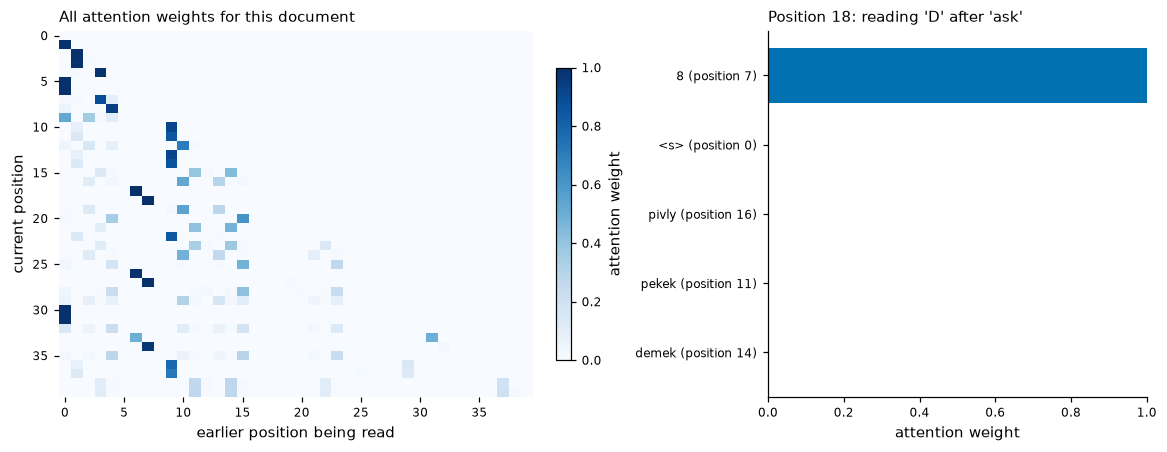

document: <s> vazis tovur titek sorom set D 8 fuda ruris tovur pekek ruris tovur demek vabom pivly ask D 8 peza vabom titek vabom ludly sina ask D 8 ruris set E 6 ask D 8 potur dasek lunom vabom
queried keys at positions [18, 27, 34] -> most attended earlier position: [7, 7, 7] holding ['8', '8', '8']


In [11]:
att_model = models["LSTM + dot-product attention"]
def attention_of(doc):
    with torch.no_grad():
        return att_model(torch.as_tensor(doc)[None], return_weights=True)[1][0].numpy()      # [t, j]: state t looking at state j
doc_id = int(np.argmax((test["kind"][:200, :40] == W.K_QVAL).sum(1) >= 3))
doc = test["tokens"][doc_id][:40]
A = attention_of(doc)
words = [W.WORDS[t] for t in doc]
fig, ax = plt.subplots(figsize=(10.5, 2.2))
def frame(t):
    ax.clear()
    vals = np.zeros(len(doc)); vals[:t] = A[t, :t]
    edge = [None] * len(doc); edge[t] = viz.VERMILION
    viz.token_strip(ax, words, values=vals, vmax=1.0, wrap=20, fontsize=7, edge=edge)
    nxt = words[t + 1] if t + 1 < len(doc) else ""
    ax.set_title(f"Reading '{words[t]}' (outlined). Shading = attention over earlier tokens. Next token to predict: '{nxt}'")
viz.save_gif(fig, frame, range(1, len(doc) - 1), "nb02_attention_reading.gif", fps=2)

qpos = [t for t in range(len(doc)) if test["kind"][doc_id][t] == W.K_QKEY]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), gridspec_kw=dict(width_ratios=[1.25, 1]))
viz.heat(axes[0], A, cmap="Blues", vmin=0, vmax=1, cbar="attention weight")
axes[0].set_xlabel("earlier position being read"); axes[0].set_ylabel("current position"); axes[0].set_title("All attention weights for this document")
q = qpos[0]
top = np.argsort(-A[q, :q])[:5][::-1]
axes[1].barh([f"{words[j]} (position {j})" for j in top], A[q, top], color=viz.BLUE)
axes[1].set_xlabel("attention weight"); axes[1].set_xlim(0, 1)
axes[1].set_title(f"Position {q}: reading '{words[q]}' after 'ask'")
plt.show()
print("document:", " ".join(words))
print("queried keys at positions", qpos, "-> most attended earlier position:", [int(A[p, :p].argmax()) for p in qpos],
      "holding", [words[int(A[p, :p].argmax())] for p in qpos])

![The attention model reading a document; when it reaches a queried key, attention jumps back to the binding](figures/nb02_attention_reading.gif)

For most tokens the attention is spread thinly or sits on recent tokens. At each of the three queries for key `D`
(positions 18, 27 and 34) nearly all of it lands on position 7, the value `8` that was bound to `D`, however far back
that is. The model has learned to use attention as a lookup.

### Try it: pick a document and a position

Static preview at the default settings {'document': 0, 'position': 34}. Run the notebook to get the controls.


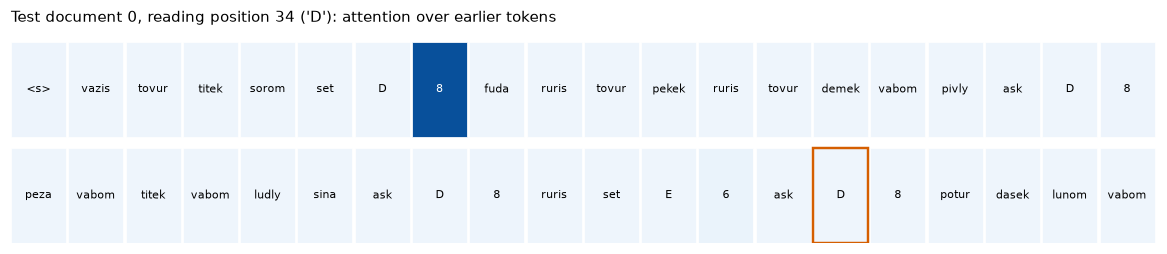

In [12]:
def attention_explorer(document=0, position=20):
    doc = test["tokens"][document][:40]
    A = attention_of(doc)
    position = min(position, len(doc) - 1)
    vals = np.zeros(len(doc)); vals[:position] = A[position, :position]
    edge = [None] * len(doc); edge[position] = viz.VERMILION
    fig, ax = plt.subplots(figsize=(10.5, 2.2))
    viz.token_strip(ax, [W.WORDS[t] for t in doc], values=vals, vmax=1.0, wrap=20, fontsize=7, edge=edge)
    ax.set_title(f"Test document {document}, reading position {position} ('{W.WORDS[doc[position]]}'): attention over earlier tokens")
    plt.show()
viz.explore(attention_explorer, document=(0, 50, 1, doc_id), position=(1, 39, 1, qpos[-1]))

## 5. The cost that remains: one step at a time

Attention fixed the memory. It did not change how the states are computed: $h_t$ needs $h_{t-1}$, which needs
$h_{t-2}$, and so on. The steps along a sequence cannot be run side by side. We time a training step on the same
number of tokens arranged as many short sequences or as few long ones.

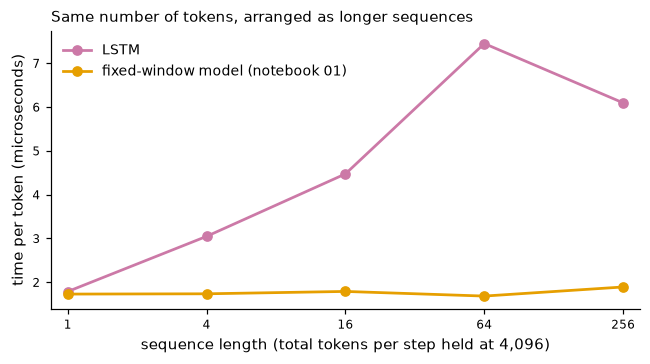

,LSTM,fixed-window model
1,1.8,1.7
4,3.0,1.7
16,4.5,1.8
64,7.4,1.7
256,6.1,1.9


In [13]:
def microseconds_per_token(model, length, total=4096, reps=5):
    x = torch.randint(5, W.VOCAB, (total // length, length)); opt = torch.optim.SGD(model.parameters(), 1e-3)
    best = np.inf
    for _ in range(reps):
        t0 = time.time()
        loss = model(x).logsumexp(-1).mean(); opt.zero_grad(); loss.backward(); opt.step()
        best = min(best, time.time() - t0)
    return 1e6 * best / total
lengths = [1, 4, 16, 64, 256]
timing = pd.DataFrame({"LSTM": [microseconds_per_token(R.RecurrentLM("lstm", d=64), L) for L in lengths],
                       "fixed-window model": [microseconds_per_token(C.WindowMLP(8), L) for L in lengths]}, index=lengths)
fig, ax = plt.subplots(figsize=(5.8, 3.2))
ax.plot(lengths, timing["LSTM"], "o-", color=COL["LSTM"], label="LSTM")
ax.plot(lengths, timing["fixed-window model"], "o-", color=viz.FAMILY["window MLP"], label="fixed-window model (notebook 01)")
ax.set_xscale("log", base=2); ax.set_xticks(lengths); ax.set_xticklabels(lengths)
ax.set_xlabel("sequence length (total tokens per step held at 4,096)"); ax.set_ylabel("time per token (microseconds)"); ax.legend()
ax.set_title("Same number of tokens, arranged as longer sequences")
plt.show()
display(timing.round(1))

**Reading the result.** The fixed-window model costs the same per token however the tokens are arranged, because
every position is computed independently. The LSTM costs about four times more per token when the same tokens come as
64-token sequences rather than single tokens, because each step must wait for the one before. On hardware built for
parallel work the difference is much larger, and it limited how much data recurrent models could be trained on.

## 6. Contextual pretraining: reusing the language model

Everything so far was about predicting the next token. The step that turned language models into *pretrained* models
was the observation that a network trained this way has learned things that other tasks need. [Dai & Le, 2015](https://arxiv.org/abs/1511.01432) initialised
a classifier from a language model. **ELMo** ([Peters et al., 2018](https://arxiv.org/abs/1802.05365)) took the hidden states of a pretrained LSTM language
model as word representations, **contextual embeddings**, and improved a wide range of tasks by feeding them to
existing task models. **ULMFiT** ([Howard & Ruder, 2018](https://arxiv.org/abs/1801.06146)) fine-tuned the whole pretrained network.

The difference from notebook 01's embeddings is in the name. A skip-gram vector is the same in every sentence. A
hidden state depends on everything read so far. The figure takes one word and plots the LSTM's state at 300 of its
occurrences in different documents.

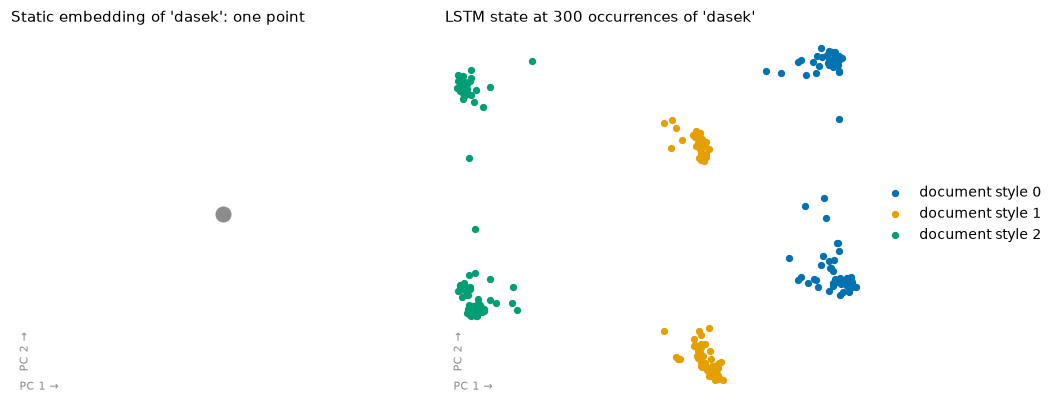

In [14]:
probe_docs = W.corpus("probe")
word = int(np.bincount(probe_docs["tokens"][:, 20:].ravel(), minlength=W.VOCAB)[W.FILL0:].argmax()) + W.FILL0
with torch.no_grad():
    H = models["LSTM"].states(torch.as_tensor(probe_docs["tokens"][:1500])).numpy()
d_idx, p_idx = np.nonzero(probe_docs["tokens"][:1500, 20:] == word)
d_idx, p_idx = d_idx[:300], p_idx[:300] + 20
P = viz.pca2(H[d_idx, p_idx])
style = probe_docs["style"][d_idx]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
axes[0].scatter([0], [0], s=90, color=viz.GREY); viz.embedding_axes(axes[0])
axes[0].set_title(f"Static embedding of '{W.WORDS[word]}': one point")
for s, col in zip(range(3), [viz.BLUE, viz.ORANGE, viz.GREEN]):
    axes[1].scatter(P[style == s, 0], P[style == s, 1], s=14, color=col, label=f"document style {s}")
viz.embedding_axes(axes[1]); axes[1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
axes[1].set_title(f"LSTM state at 300 occurrences of '{W.WORDS[word]}'")
plt.show()

The same word gets a different vector depending on the document it is in, and the vectors group by the document's
hidden style, which the model was never told about. (Within a style there are several groups, which reflect the words
just before.) The model had to work the style out to predict the next word well.

Now the transfer experiment. The task is to predict a document's style from a handful of labelled documents. We
compare four approaches as the number of labels grows:

* **word counts**: the static baseline from notebook 01;
* **from scratch**: a fresh LSTM classifier trained only on the labelled documents;
* **frozen features** (ELMo-style): average the pretrained LSTM's states and fit a linear classifier on top;
* **fine-tuning** (ULMFiT-style): start from the pretrained LSTM and train all of it, with a ten-times smaller
  learning rate for the pretrained part.

,word counts,LSTM from scratch,"pretrained, frozen features","pretrained, fine-tuned"
15,0.332,0.345,1.0,0.972
30,0.342,0.394,1.0,0.957
100,0.341,0.489,1.0,0.971
300,0.355,0.850,1.0,0.978
1000,0.386,0.970,1.0,0.987


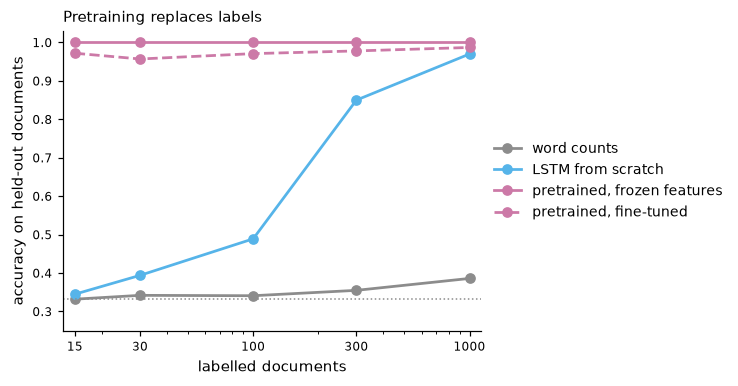

In [15]:
Xte, yte = probe_docs["tokens"][3000:], probe_docs["style"][3000:]
counts = lambda tok: np.stack([np.bincount(t, minlength=W.VOCAB) for t in tok]).astype(float)
label_counts = [15, 30, 100, 300, 1000]
transfer = {k: [] for k in ["word counts", "LSTM from scratch", "pretrained, frozen features", "pretrained, fine-tuned"]}
for n in label_counts:
    idx = np.random.default_rng(0).permutation(3000)[:n]
    Xn, yn = probe_docs["tokens"][idx], probe_docs["style"][idx]
    transfer["word counts"].append(W.probe(counts, n, "style"))
    transfer["pretrained, frozen features"].append(W.probe(models["LSTM"].features, n, "style"))
    set_seed(0)
    scratch = R.train_classifier(R.Classifier(R.RecurrentLM("lstm", d=64)), Xn, yn, steps=300)
    transfer["LSTM from scratch"].append(R.classifier_accuracy(scratch, Xte, yte))
    tuned = R.train_classifier(R.Classifier(copy.deepcopy(models["LSTM"])), Xn, yn, steps=300, lr_encoder=2e-4)
    transfer["pretrained, fine-tuned"].append(R.classifier_accuracy(tuned, Xte, yte))
transfer = pd.DataFrame(transfer, index=label_counts)
display(transfer.round(3))
fig, ax = plt.subplots(figsize=(6.6, 3.4))
for name, col, ls in zip(transfer, [viz.GREY, viz.SKY, viz.PINK, viz.PINK], ["-", "-", "-", "--"]):
    ax.plot(label_counts, transfer[name], "o", ls=ls, color=col, label=name)
ax.axhline(1 / 3, color=viz.GREY, ls=":", lw=1)
ax.set_xscale("log"); ax.set_xticks(label_counts); ax.set_xticklabels(label_counts); ax.set_ylim(0.25, 1.03)
ax.set_xlabel("labelled documents"); ax.set_ylabel("accuracy on held-out documents")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5)); ax.set_title("Pretraining replaces labels")
plt.show()

**Reading the result.** With 15 labelled documents, a linear classifier on the frozen pretrained features is already
at 100%. A model trained from scratch is at chance with 15 or 30 labels and needs about 1,000 to reach 97%. Word counts
never get beyond 39%. Fine-tuning lands slightly below the frozen features (96 to 99%): with this few labels, changing
the pretrained weights loses a little of what they knew (Challenge Problem 2 looks at this). The language model was
trained on 20,000 unlabelled documents, which cost nothing to label, and that is the trade pre-training offers.

## 7. Design choices: what changed since

| Choice | Original | What the field moved to | Why |
|---|---|---|---|
| Recurrent unit | plain tanh RNN ([Elman, 1990](https://doi.org/10.1207/s15516709cog1402_1)) | LSTM ([Hochreiter & Schmidhuber, 1997](https://doi.org/10.1162/neco.1997.9.8.1735)), GRU ([Cho et al., 2014](https://arxiv.org/abs/1406.1078)) | Additive cell and gates let the training signal survive many steps (ablated in section 3) |
| Exploding gradients | none | clipping the gradient norm ([Pascanu et al., 2012](https://arxiv.org/abs/1211.5063)) | Bounds each update (ablated in section 2); still standard |
| Reaching the past | through the state only | attention over past states ([Bahdanau et al., 2014](https://arxiv.org/abs/1409.0473)) | Removes the fixed-size bottleneck (section 4) |
| Attention score | additive network | scaled dot product ([Luong et al., 2015](https://arxiv.org/abs/1508.04025)) | One matrix product for all pairs (ablated in section 4) |
| Using a pretrained model | frozen features (ELMo, [Peters et al., 2018](https://arxiv.org/abs/1802.05365)) | fine-tuning everything, with smaller learning rates for earlier layers and gradual unfreezing (ULMFiT, [Howard & Ruder, 2018](https://arxiv.org/abs/1801.06146)) | Adapts the features to the task (compared in section 6; Challenge Problem 2) |
| Direction | left to right | two language models, one per direction, combined (ELMo) | Uses context on both sides of a word; notebook 04 returns to this |

## 8. Scorecard

In [16]:
rows = []
for name in models:
    rows.append(W.scorecard_row("LSTM, 64 units" if name == "LSTM" else name, res[name],
                                recall_natural=res[name]["natural"].correct.mean(), probe_style=W.probe(models[name].features, 100, "style"),
                                params=sum(p.numel() for p in models[name].parameters()), train_seconds=res[name]["seconds"]))
metrics.append_rows(rows, "02_recurrent")
display(metrics.load_scorecard()[["notebook", "model", "gap", "recall_d8", "recall_d32", "recall_natural", "probe_style", "train_seconds"]].round(3))

,notebook,model,gap,recall_d8,recall_d32,recall_natural,probe_style,train_seconds
0,01_ngrams_embeddings,unigram,1.714,0.000,0.000,NaN,NaN,NaN
1,01_ngrams_embeddings,"n-gram, Kneser-Ney, n=3",0.662,0.138,0.110,NaN,NaN,NaN
2,01_ngrams_embeddings,"n-gram, Kneser-Ney, n=6",0.835,0.128,0.138,NaN,NaN,NaN
3,01_ngrams_embeddings,"window neural LM, 4 tokens",0.483,0.150,0.130,NaN,NaN,9.493
4,01_ngrams_embeddings,"window neural LM, 16 tokens",0.269,1.000,0.144,NaN,NaN,18.271
5,01_ngrams_embeddings,"skip-gram embeddings, averaged",NaN,NaN,NaN,NaN,0.411,NaN
6,02_recurrent,plain RNN,0.326,0.132,0.114,0.137,0.997,12.634
7,02_recurrent,GRU,0.243,0.154,0.128,0.153,1.000,39.122
8,02_recurrent,"LSTM, 64 units",0.170,0.850,0.662,0.546,1.000,43.919
9,02_recurrent,"LSTM, 128 units",0.080,1.000,1.000,0.651,1.000,68.919


## Challenge Problem 1: Longer than anything seen in training

Every training document has 64 tokens. Build recall tests at distances of 80, 120 and 200 tokens with `W.recall_set(d, n=300, length=d + 8)` and
measure recall for the 128-unit LSTM and for the two attention models. Which models still work at distances they were never trained on? Suggest a
reason for any that do not.

In [17]:
# Start your code here

### Challenge Problem 1 Solution

In [18]:
def recall_at(model, d, n=300):
    t, pos = W.recall_set(d, n=n, length=d + 8)
    return float((model.logprobs(t[:, :pos + 1])[:, pos].argmax(-1) == t[:, pos]).mean())
far = pd.DataFrame({name: [recall_at(models[name], d) for d in [56, 80, 120, 200]]
                    for name in ["LSTM, 128 units", "LSTM + dot-product attention", "LSTM + additive attention"]}, index=[56, 80, 120, 200])
far.index.name = "distance"; display(far.round(2))
# Read the table. The 128-unit LSTM and the dot-product attention model both keep working far beyond the 64 tokens
# they were trained on (the LSTM slips a little at 200). A carried memory has no built-in length limit, and this
# attention has no notion of position at all: it matches content, so distance does not matter to it. The additive
# model was already imperfect inside the training length and gets steadily worse outside it. Whether attention models
# generalise to longer inputs depends on how position is represented, which notebook 03 examines.

,"LSTM, 128 units",LSTM + dot-product attention,LSTM + additive attention
distance,,,
56,1.00,1.0,0.75
80,1.00,1.0,0.69
120,1.00,1.0,0.59
200,0.92,1.0,0.35


## Challenge Problem 2: How fast should the pretrained part learn?

Fine-tune the pretrained LSTM on 30 labelled documents with three learning rates for the pretrained part: the same as the new classifier layer
(`2e-3`), ten times smaller (`2e-4`) and zero (frozen). Use `R.train_classifier(..., lr_encoder=...)`, three seeds each, and report the mean
accuracy. Relate the result to ULMFiT's advice to use smaller learning rates for pretrained layers.

In [19]:
# Start your code here

### Challenge Problem 2 Solution

In [20]:
idx = np.random.default_rng(1).permutation(3000)[:30]
Xn, yn = probe_docs["tokens"][idx], probe_docs["style"][idx]
out = {}
for lr_enc in [2e-3, 2e-4, 0.0]:
    accs = []
    for seed in range(3):
        m = R.train_classifier(R.Classifier(copy.deepcopy(models["LSTM"])), Xn, yn, steps=300, lr_encoder=lr_enc, seed=seed)
        accs.append(R.classifier_accuracy(m, Xte, yte))
    out[f"encoder learning rate {lr_enc:g}"] = (np.mean(accs), np.min(accs), np.max(accs))
display(pd.DataFrame(out, index=["mean", "min", "max"]).T.round(3))
# Read the table: with 30 labels there is very little evidence to justify moving a network that already works.
# A large learning rate on the pretrained weights can overwrite what pre-training learned (the forgetting that the
# post-training series measures at length); a small one adapts gently; zero keeps the features fixed. ULMFiT's
# discriminative learning rates and gradual unfreezing are ways of managing exactly this trade-off.

,mean,min,max
encoder learning rate 0.002,0.794,0.787,0.799
encoder learning rate 0.0002,0.975,0.970,0.978
encoder learning rate 0,0.997,0.996,0.998


## Final summary

* A recurrent network has no window, but a plain one cannot *learn* to use its memory: the training signal shrinks
  exponentially with distance (or explodes, which clipping handles).
* **Gating** (LSTM, GRU) gives the signal a path that survives many steps. The remaining limit is capacity: the past
  must fit in one fixed-size state.
* **Attention** gives every earlier position a direct route to the present, which removes that bottleneck.
* A network trained only to predict the next token learns **contextual representations** that transfer: with a few
  labelled documents, a pretrained model does what a model trained from scratch needs far more labels to do. This is
  the start of pre-training as we use the word today.
* What remains is cost. A recurrent network computes its states one after another. Notebook 03 keeps the attention
  and removes the recurrence.

## References

* Jeffrey L. Elman (1990). **Finding Structure in Time**. *Cognitive Science*. [doi.org/10.1207/s15516709cog1402_1](https://doi.org/10.1207/s15516709cog1402_1)
* Y. Bengio, P. Simard, P. Frasconi (1994). **Learning long-term dependencies with gradient descent is difficult**. *IEEE Transactions on Neural Networks*. [doi.org/10.1109/72.279181](https://doi.org/10.1109/72.279181)
* Sepp Hochreiter, Jürgen Schmidhuber (1997). **Long Short-Term Memory**. *Neural Computation*. [doi.org/10.1162/neco.1997.9.8.1735](https://doi.org/10.1162/neco.1997.9.8.1735)
* Kyunghyun Cho, Bart van Merrienboer, Caglar Gulcehre et al. (2014). **Learning Phrase Representations using RNN Encoder-Decoder for Statistical Machine Translation**. arXiv:1406.1078. [arxiv.org/abs/1406.1078](https://arxiv.org/abs/1406.1078)
* Razvan Pascanu, Tomas Mikolov, Yoshua Bengio (2012). **On the difficulty of training Recurrent Neural Networks**. arXiv:1211.5063. [arxiv.org/abs/1211.5063](https://arxiv.org/abs/1211.5063)
* Ilya Sutskever, Oriol Vinyals, Quoc V. Le (2014). **Sequence to Sequence Learning with Neural Networks**. arXiv:1409.3215. [arxiv.org/abs/1409.3215](https://arxiv.org/abs/1409.3215)
* Dzmitry Bahdanau, Kyunghyun Cho, Yoshua Bengio (2014). **Neural Machine Translation by Jointly Learning to Align and Translate**. arXiv:1409.0473. [arxiv.org/abs/1409.0473](https://arxiv.org/abs/1409.0473)
* Minh-Thang Luong, Hieu Pham, Christopher D. Manning (2015). **Effective Approaches to Attention-based Neural Machine Translation**. arXiv:1508.04025. [arxiv.org/abs/1508.04025](https://arxiv.org/abs/1508.04025)
* Andrew M. Dai, Quoc V. Le (2015). **Semi-supervised Sequence Learning**. arXiv:1511.01432. [arxiv.org/abs/1511.01432](https://arxiv.org/abs/1511.01432)
* Matthew E. Peters, Mark Neumann, Mohit Iyyer et al. (2018). **Deep contextualized word representations**. arXiv:1802.05365. [arxiv.org/abs/1802.05365](https://arxiv.org/abs/1802.05365)
* Jeremy Howard, Sebastian Ruder (2018). **Universal Language Model Fine-tuning for Text Classification**. arXiv:1801.06146. [arxiv.org/abs/1801.06146](https://arxiv.org/abs/1801.06146)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).